# ATP Binding Interaction Analysis

**Goal:** Characterise how ATP binds across thousands of PDB structures, identify
conserved interaction archetypes, and find design handles for complementary binding
proteins that assemble in response to ATP.

## Workflow
| Step | What happens |
|---|---|
| 1 | Select PDB structures from the existing cache |
| 2 | Run **PLIP** on each structure to detect protein–ATP interactions |
| 3 | Parse H-bonds, hydrophobic contacts, π-stacking, salt bridges, metal coordination |
| 4 | Encode each structure as a binary interaction fingerprint |
| 5 | Cluster by fingerprint similarity (hierarchical, Jaccard distance) |
| 6 | Visualise as a Epiclus-style interaction heatmap |
| 7 | Profile each cluster: signature residues and interaction types |
| 8 | Identify which ATP moieties are most exposed → design recommendations |

---
**Checkpointing:** PLIP results are cached in `atp_binding_output/plip_results/` (one XML per
structure). Re-running Step 2 is instant for already-processed structures. The parsed
interaction table is also checkpointed as `atp_interactions.csv`.

## Environment setup (run once, then restart kernel)

Create a dedicated environment that has PLIP, RDKit, and analysis tools:

```bash
conda create -n atp_project_env python=3.11 -y
conda activate atp_project_env
conda install -c conda-forge openbabel rdkit -y
pip install plip biopython pandas numpy scipy matplotlib seaborn scikit-learn umap-learn tqdm
```

Then set this notebook's kernel to **atp_project_env**.

> Until the new environment is ready, the existing **epiclus_env** works for everything
> except RDKit. Set the kernel to `epiclus_env` via *Kernel → Change Kernel* in JupyterLab.

In [1]:
# ─── Parameters — edit before running ─────────────────────────────────────────
PDB_CACHE_DIR = 'pdb_cache'              # existing cache from conformer analysis
OUTPUT_DIR    = 'output/binding'   # data output directory (sub-folder of output/)
PLOT_DIR      = 'pictures'          # PNG plots (shared with conformer analysis)

N_STRUCTURES  = 100    # None = all ~3500; start small to explore, then scale up
N_WORKERS     = 6      # parallel PLIP threads (PLIP runs as subprocess → threads are fine)
N_CLUSTERS    = 7      # number of clusters for hierarchical clustering
MIN_CONTACTS  = 4      # discard structures with fewer distinct contact features
HEATMAP_FREQ  = 0.04   # minimum fraction of structures a feature must appear in to be shown

In [2]:
%matplotlib inline
import os, sys, json, subprocess, shutil
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from tqdm import tqdm

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
Path(PLOT_DIR).mkdir(exist_ok=True)

# Detect PLIP executable in the active conda environment
PLIP_EXE = shutil.which('plip') or os.path.join(os.path.dirname(sys.executable), 'plip')
if not Path(PLIP_EXE).exists():
    raise EnvironmentError(
        f"PLIP not found at '{PLIP_EXE}'.\n"
        "Install it with:  conda install -c conda-forge openbabel && pip install plip"
    )
print(f'PLIP executable : {PLIP_EXE}')

AA3 = {
    'ALA':'A','ARG':'R','ASN':'N','ASP':'D','CYS':'C','GLN':'Q','GLU':'E',
    'GLY':'G','HIS':'H','ILE':'I','LEU':'L','LYS':'K','MET':'M','PHE':'F',
    'PRO':'P','SER':'S','THR':'T','TRP':'W','TYR':'Y','VAL':'V'
}

# Human-readable labels for PLIP interaction group tags
ITYPE_LABEL = {
    'hydrogen_bonds':         'HBond',
    'hydrophobic_interactions':'HPhob',
    'salt_bridges':           'Salt',
    'pi_stacks':              'PiStack',
    'pi_cation_interactions':  'PiCat',
    'metal_complexes':        'Metal',
    'water_bridges':          'WaterBr',
    'halogen_bonds':          'Halogen',
}

ITYPE_COLOR = {
    'HBond':   '#1f77b4',
    'HPhob':   '#2ca02c',
    'Salt':    '#d62728',
    'PiStack': '#ff7f0e',
    'PiCat':   '#9467bd',
    'Metal':   '#8c564b',
    'WaterBr': '#17becf',
    'Halogen': '#e377c2',
}

print('Setup OK.')

PLIP executable : /work3/s212001/miniforge3/envs/atp_project_env/bin/plip
Setup OK.


## Helper functions
Run once — used across all steps below.

In [3]:
def run_plip(pdb_path: str, plip_dir: str) -> str | None:
    """Run PLIP on a PDB file; return path to *_report.xml, or None on failure.
    PLIP 3.x writes <pdbid>_report.xml instead of report.xml."""
    Path(plip_dir).mkdir(parents=True, exist_ok=True)
    # PLIP 3.x names the output <stem>_report.xml; check cache first
    existing = list(Path(plip_dir).glob('*_report.xml'))
    if existing:
        return str(existing[0])
    try:
        subprocess.run(
            [PLIP_EXE, '-f', str(pdb_path), '-x', '-o', str(plip_dir)],
            capture_output=True, text=True, timeout=120, check=True,
        )
    except Exception:
        return None
    found = list(Path(plip_dir).glob('*_report.xml'))
    return str(found[0]) if found else None


def parse_atp_xml(xml_path: str, pdb_id: str) -> pd.DataFrame:
    """Parse a PLIP XML report; return a DataFrame of ATP-protein interactions."""
    try:
        root = ET.parse(xml_path).getroot()
    except Exception:
        return pd.DataFrame()

    records = []
    for bs in root.findall('.//bindingsite'):
        if bs.findtext('./identifiers/hetid', '') != 'ATP':
            continue                  # skip non-ATP binding sites
        atp_id = (f"{bs.findtext('./identifiers/chain','')}:"
                  f"{bs.findtext('./identifiers/position','')}")
        interacts = bs.find('interactions')
        if interacts is None:
            continue

        for igroup in interacts:     # iterate over interaction type groups
            raw = igroup.tag         # e.g. 'hydrogen_bonds', 'salt_bridges', ...
            label = ITYPE_LABEL.get(raw, raw)
            for item in igroup:
                resnr    = item.findtext('resnr',    '')
                restype  = item.findtext('restype',  '')
                reschain = item.findtext('reschain', '')

                # For H-bonds, distinguish direction (protein donor vs acceptor)
                if raw == 'hydrogen_bonds':
                    pdon  = item.findtext('protisdon', 'True')
                    label = 'HBond_Don' if pdon == 'True' else 'HBond_Acc'

                records.append({
                    'pdb_id':    pdb_id,
                    'atp_id':    atp_id,
                    'res_nr':    resnr,
                    'res_type':  restype,
                    'res_1':     AA3.get(restype, 'X'),
                    'itype':     label,
                    'itype_raw': raw,
                })
    return pd.DataFrame(records)


def _worker(pdb_id: str) -> tuple:
    """Thread worker: run PLIP + parse for one PDB. Returns (pdb_id, df | None)."""
    pdb_path = Path(PDB_CACHE_DIR) / f'{pdb_id.lower()}.pdb'
    if not pdb_path.exists():
        return pdb_id, None
    plip_dir = Path(OUTPUT_DIR) / 'plip_results' / pdb_id
    xml_path = run_plip(str(pdb_path), str(plip_dir))
    if xml_path is None:
        return pdb_id, None
    df = parse_atp_xml(xml_path, pdb_id)
    return pdb_id, df if not df.empty else None


print('Helper functions loaded.')

Helper functions loaded.


---
## Step 1 — Select structures
Reads PDB IDs directly from the cache built during conformer analysis.
Set `N_STRUCTURES = None` to process all ~3,500 structures (takes ~2–4 h).

In [4]:
all_pdb_ids = sorted(p.stem.upper() for p in Path(PDB_CACHE_DIR).glob('*.pdb'))
print(f'PDB files in cache: {len(all_pdb_ids):,}')

pdb_ids = all_pdb_ids[:N_STRUCTURES] if N_STRUCTURES else all_pdb_ids
print(f'Selected for analysis: {len(pdb_ids):,}'
      + (f'  (set N_STRUCTURES=None to use all)' if N_STRUCTURES else ''))

PDB files in cache: 2,933
Selected for analysis: 100  (set N_STRUCTURES=None to use all)


---
## Step 2 — Run PLIP

PLIP analyses the complete protein structure and detects all interactions between
the ATP ligand and surrounding protein residues:
hydrogen bonds (donor / acceptor), hydrophobic contacts, π-stacking,
π-cation, salt bridges, metal coordination, and water-mediated H-bonds.

Each structure's result is cached as an XML file — re-running this cell is fast
for structures already processed.

In [5]:
PLIP_DIR = Path(OUTPUT_DIR) / 'plip_results'
n_cached = sum(1 for pid in pdb_ids
               if (PLIP_DIR / pid / 'report.xml').exists())
print(f'Running PLIP on {len(pdb_ids)} structures  '
      f'({n_cached} already cached, {len(pdb_ids)-n_cached} to compute)')
print(f'Workers: {N_WORKERS}  |  estimated time for new runs: '
      f'~{max(0,(len(pdb_ids)-n_cached))*4//N_WORKERS//60} min')

results = {}
failed  = []

with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
    futures = {pool.submit(_worker, pid): pid for pid in pdb_ids}
    for fut in tqdm(as_completed(futures), total=len(pdb_ids), desc='PLIP'):
        pid, df = fut.result()
        if df is not None:
            results[pid] = df
        else:
            failed.append(pid)

print(f'\nSucceeded: {len(results):,}  |  Failed / no ATP found: {len(failed):,}')

Running PLIP on 100 structures  (0 already cached, 100 to compute)
Workers: 6  |  estimated time for new runs: ~1 min


PLIP: 100%|██████████| 100/100 [00:00<00:00, 184.21it/s]


Succeeded: 98  |  Failed / no ATP found: 2


---
## Step 3 — Interaction dataframe
Combines all per-structure results into one master table and saves it as a CSV
checkpoint. Loads from checkpoint if it already exists.

In [6]:
CSV_PATH = Path(OUTPUT_DIR) / 'atp_interactions.csv'

if results:
    df_all = pd.concat(results.values(), ignore_index=True)
    df_all.to_csv(CSV_PATH, index=False)
    print(f'Saved {len(df_all):,} interaction records to {CSV_PATH}')
elif CSV_PATH.exists():
    df_all = pd.read_csv(CSV_PATH)
    print(f'Loaded {len(df_all):,} records from checkpoint {CSV_PATH}')
else:
    raise RuntimeError('No results and no checkpoint found. Run Step 2 first.')

print(f'Structures with ATP contacts: {df_all["pdb_id"].nunique():,}')
print()
print('Interaction type breakdown:')
print(df_all['itype'].value_counts().to_string())
print()
print('Top 12 contacting residue types:')
print(df_all['res_type'].value_counts().head(12).to_string())

Saved 3,791 interaction records to output/binding/atp_interactions.csv
Structures with ATP contacts: 98

Interaction type breakdown:
itype
HBond_Don    1455
Salt          640
HBond_Acc     560
Metal         535
WaterBr       487
PiStack        63
PiCat          42
HPhob           9

Top 12 contacting residue types:
res_type
LYS    555
ARG    452
GLY    409
THR    338
ATP    260
GLU    256
ASP    254
SER    245
HOH    173
GLN    117
ASN    107
HIS    100


---
## Step 4 — Interaction fingerprints

Each structure is encoded as a **binary vector** where each feature is a
(residue_type, interaction_type) pair. A `1` means at least one residue of that
type makes that interaction type with ATP in this structure.

This representation ignores copy number and focuses on the *types* of contacts present,
making it robust to differences in the number of ATP copies per structure.

In [7]:
# Build binary fingerprint matrix: rows = structures, columns = (res_type, itype)
fp_raw = (
    df_all
    .groupby(['pdb_id', 'res_type', 'itype'])
    .size()
    .reset_index(name='count')
    .pivot_table(index='pdb_id', columns=['res_type', 'itype'],
                 values='count', aggfunc='sum')
    .fillna(0)
    .gt(0)
    .astype(int)
)

# Filter: keep structures with >= MIN_CONTACTS distinct contact features
richness = fp_raw.sum(axis=1)
fp = fp_raw[richness >= MIN_CONTACTS].copy()

print(f'Fingerprint matrix: {fp_raw.shape[0]} structures  x  {fp_raw.shape[1]} features')
print(f'After filter (>= {MIN_CONTACTS} features): {fp.shape[0]} structures kept')
print()
print('Most common features (top 20):')
top_feats = fp.sum().sort_values(ascending=False).head(20)
for (res, itype), count in top_feats.items():
    pct = count / fp.shape[0] * 100
    print(f'  {res:4s} + {itype:10s}  {count:4d}  ({pct:.0f}%)')

Fingerprint matrix: 98 structures  x  79 features
After filter (>= 4 features): 98 structures kept

Most common features (top 20):
  GLY  + HBond_Don     76  (78%)
  LYS  + Salt          72  (73%)
  ATP  + Metal         62  (63%)
  LYS  + HBond_Don     60  (61%)
  THR  + HBond_Don     59  (60%)
  SER  + HBond_Don     58  (59%)
  GLU  + HBond_Acc     54  (55%)
  HOH  + Metal         44  (45%)
  ARG  + HBond_Don     43  (44%)
  ARG  + Salt          43  (44%)
  ASP  + HBond_Acc     40  (41%)
  ASP  + HBond_Don     34  (35%)
  GLU  + HBond_Don     32  (33%)
  LEU  + HBond_Don     31  (32%)
  ARG  + WaterBr       29  (30%)
  LYS  + WaterBr       29  (30%)
  ASN  + HBond_Don     28  (29%)
  VAL  + HBond_Don     27  (28%)
  ASP  + WaterBr       27  (28%)
  GLN  + WaterBr       23  (23%)


---
## Step 5 — Hierarchical clustering

Structures are clustered using Ward linkage on Jaccard distances between fingerprints.
Jaccard distance is appropriate for binary data: it measures the fraction of features
that differ between two structures.

In [8]:
X = fp.values.astype(float)
Z = linkage(pdist(X, metric='jaccard'), method='ward')

cluster_ids = fcluster(Z, t=N_CLUSTERS, criterion='maxclust')
fp['cluster'] = cluster_ids

# Reorder rows by dendrogram leaf order
leaf_order = dendrogram(Z, no_plot=True)['leaves']
fp_ordered  = fp.iloc[leaf_order].copy()

print('Cluster sizes:')
for cid, count in sorted(pd.Series(cluster_ids).value_counts().sort_index().items()):
    print(f'  Cluster {cid}: {count} structures')

# Save cluster assignments
fp[['cluster']].to_csv(Path(OUTPUT_DIR) / 'cluster_assignments.csv')
print('\nSaved cluster assignments.')

Cluster sizes:
  Cluster 1: 20 structures
  Cluster 2: 8 structures
  Cluster 3: 30 structures
  Cluster 4: 11 structures
  Cluster 5: 12 structures
  Cluster 6: 6 structures
  Cluster 7: 11 structures

Saved cluster assignments.


---
## Step 6 — Interaction heatmap

Rows = interaction features (residue × interaction type), columns = PDB structures
sorted by cluster membership. Vertical coloured bars on top mark cluster boundaries.

Only features present in at least `HEATMAP_FREQ` of all structures are shown,
to keep the plot readable.

/tmp/ipykernel_3833658/3560754112.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


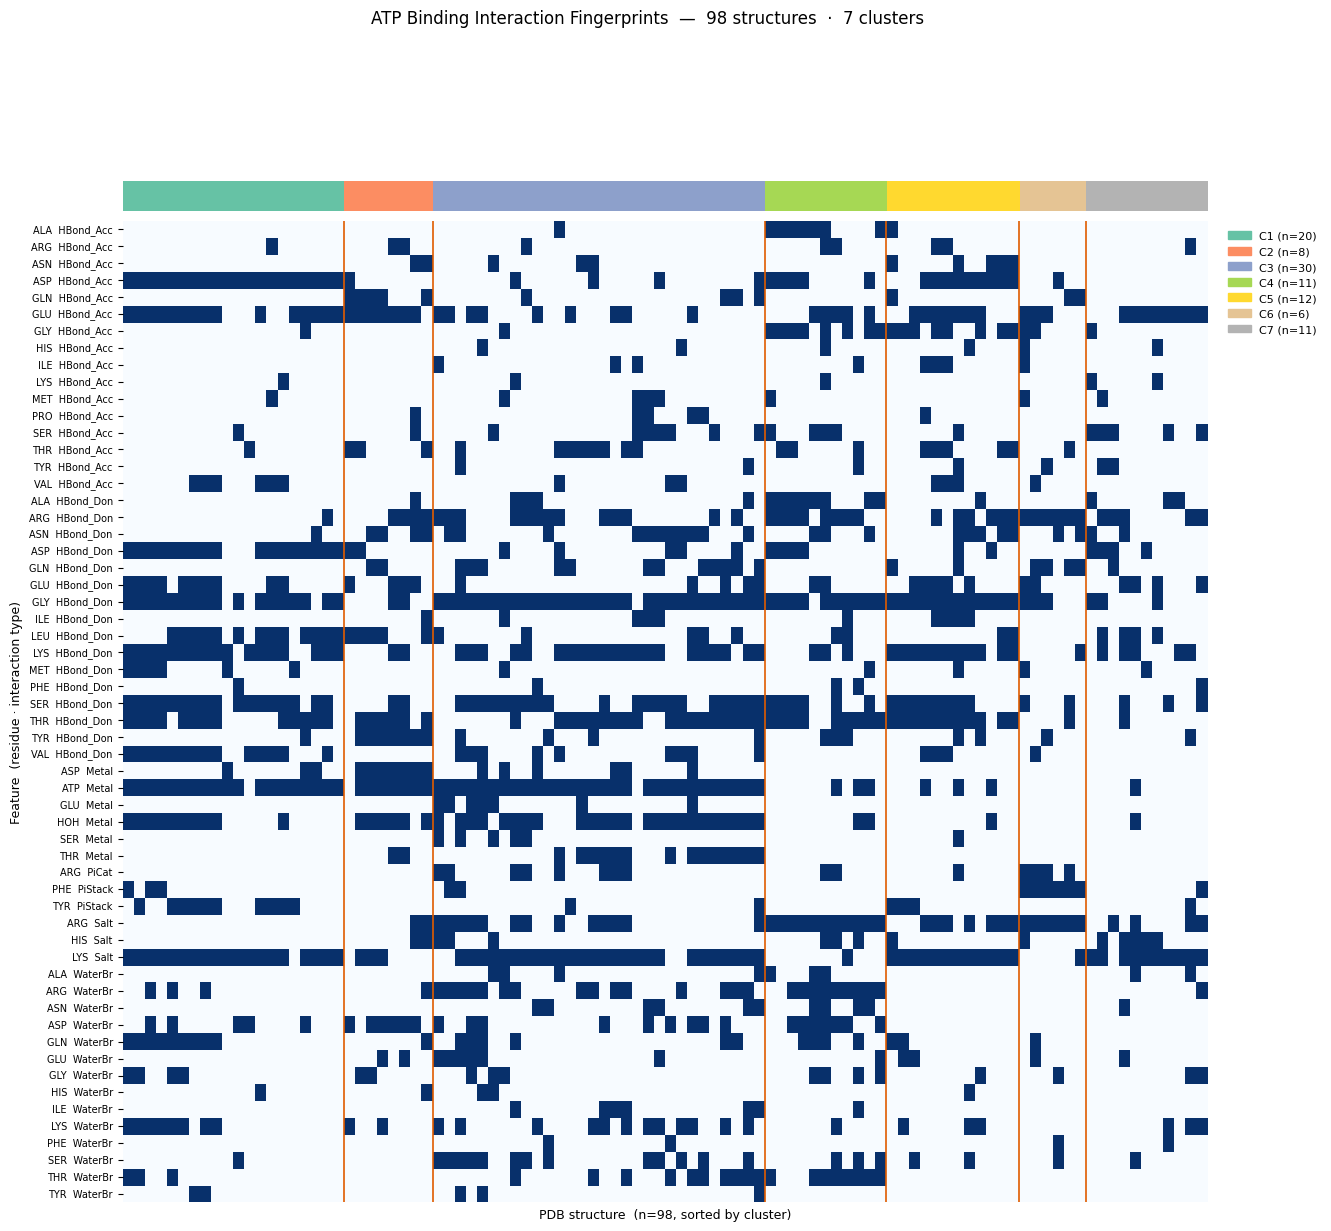

Saved interaction_heatmap.png


In [9]:
plot_data = fp_ordered.drop(columns='cluster').T

# Keep only common features
freq_mask = plot_data.sum(axis=1) / plot_data.shape[1] >= HEATMAP_FREQ
plot_data  = plot_data[freq_mask]

# Sort features by interaction type for readability
plot_data = plot_data.sort_index(level='itype')

fig_h = max(8, len(plot_data) * 0.22)
fig_w = max(14, fp_ordered.shape[0] * 0.04)
fig, (ax_top, ax_main) = plt.subplots(
    2, 1, figsize=(fig_w, fig_h + 0.5),
    gridspec_kw={'height_ratios': [0.03, 1], 'hspace': 0.02}
)

# Cluster colour bar on top
cl_palette = plt.cm.Set2(np.linspace(0, 1, N_CLUSTERS))
cl_array   = fp_ordered['cluster'].values.reshape(1, -1)
ax_top.imshow(cl_array, aspect='auto', cmap=plt.cm.Set2,
              vmin=1, vmax=N_CLUSTERS, interpolation='none')
ax_top.axis('off')

# Main heatmap
sns.heatmap(
    plot_data,
    ax=ax_main,
    cmap='Blues',
    cbar=False,
    linewidths=0,
    xticklabels=False,
    yticklabels=[f'{r}  {i}' for r, i in plot_data.index],
)
ax_main.set_ylabel('Feature  (residue · interaction type)', fontsize=9)
ax_main.set_xlabel(f'PDB structure  (n={fp_ordered.shape[0]}, sorted by cluster)', fontsize=9)
ax_main.tick_params(axis='y', labelsize=7)

# Draw vertical cluster separators
pos = 0
legend_patches = []
for cid in range(1, N_CLUSTERS + 1):
    n = (fp_ordered['cluster'] == cid).sum()
    color = cl_palette[(cid - 1) % len(cl_palette)]
    if cid < N_CLUSTERS:
        ax_main.axvline(pos + n, color='#e05c00', linewidth=1.2, zorder=5)
    legend_patches.append(mpatches.Patch(color=color, label=f'C{cid} (n={n})'))
    pos += n

ax_main.legend(
    handles=legend_patches, bbox_to_anchor=(1.01, 1),
    loc='upper left', fontsize=8, frameon=False
)

fig.suptitle(
    f'ATP Binding Interaction Fingerprints  \u2014  {fp_ordered.shape[0]} structures  \u00b7  '
    f'{N_CLUSTERS} clusters',
    fontsize=12, y=1.01
)
plt.tight_layout()
fig.savefig(Path(PLOT_DIR) / 'interaction_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved interaction_heatmap.png')

---
## Step 7 — Per-cluster interaction profiles

For each cluster: bar chart of the most frequent (residue type, interaction type)
combinations. This shows the *signature contacts* that define each binding archetype.

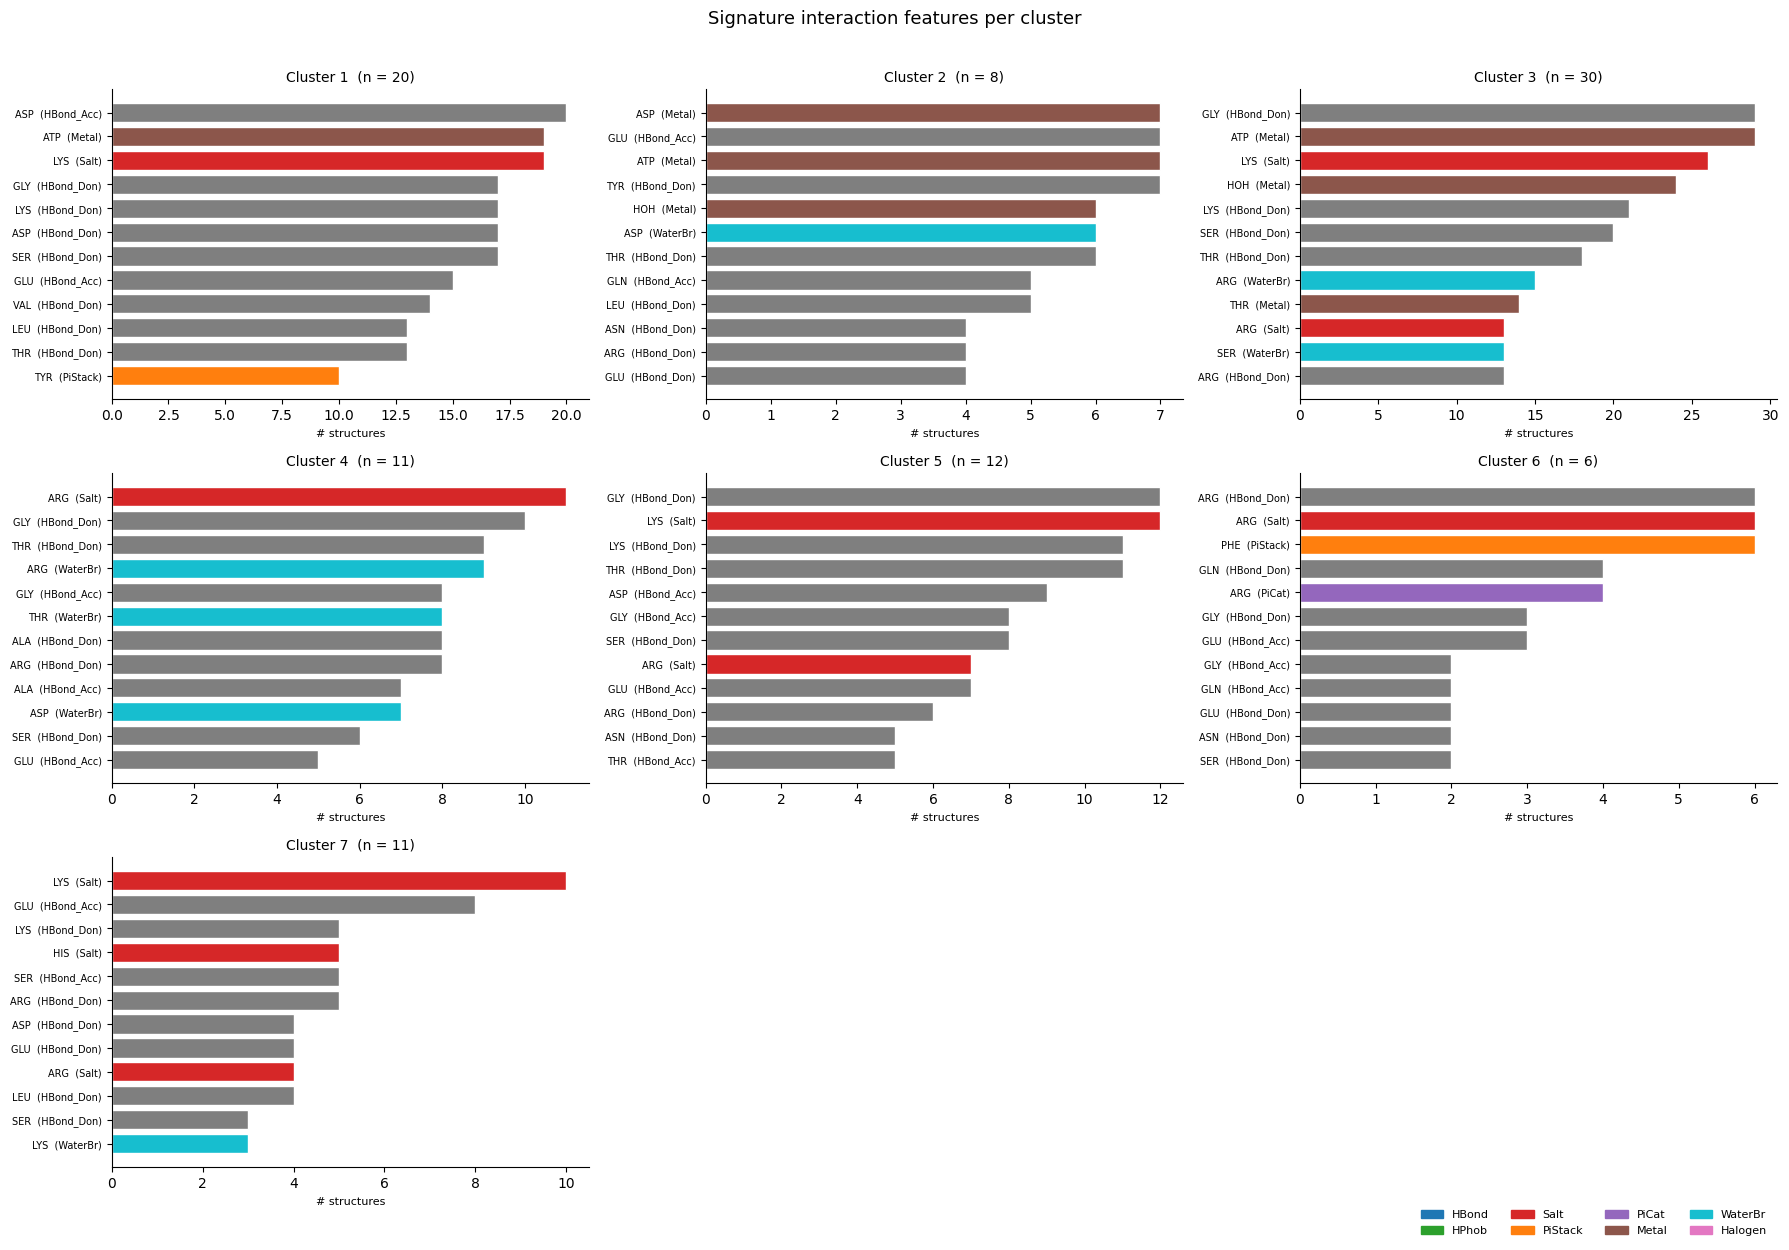

Saved cluster_profiles.png


In [10]:
n_cols = min(N_CLUSTERS, 3)
n_rows = (N_CLUSTERS + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axes = np.array(axes).flatten()

for cid in range(1, N_CLUSTERS + 1):
    ax  = axes[cid - 1]
    members = fp[fp['cluster'] == cid].index.tolist()
    cl_df   = df_all[df_all['pdb_id'].isin(members)]

    # Top features: count how many structures (not total contacts) show each feature
    feat_freq = (
        cl_df.drop_duplicates(['pdb_id', 'res_type', 'itype'])
             .groupby(['res_type', 'itype'])
             .size()
             .reset_index(name='n')
             .sort_values('n', ascending=False)
             .head(12)
    )

    bar_colors = [ITYPE_COLOR.get(i, '#7f7f7f') for i in feat_freq['itype']]
    ax.barh(range(len(feat_freq)), feat_freq['n'], color=bar_colors, edgecolor='white')
    ax.set_yticks(range(len(feat_freq)))
    ax.set_yticklabels(
        [f'{r}  ({i})' for r, i in zip(feat_freq['res_type'], feat_freq['itype'])],
        fontsize=7
    )
    ax.invert_yaxis()
    ax.set_title(f'Cluster {cid}  (n = {len(members)})', fontsize=10)
    ax.set_xlabel('# structures', fontsize=8)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

for ax in axes[N_CLUSTERS:]:
    ax.set_visible(False)

# Legend for interaction type colours
handles = [mpatches.Patch(color=c, label=k) for k, c in ITYPE_COLOR.items()]
fig.legend(handles=handles, loc='lower right', fontsize=8,
           ncol=4, bbox_to_anchor=(0.99, -0.02), frameon=False)

fig.suptitle('Signature interaction features per cluster', fontsize=13, y=1.01)
plt.tight_layout()
fig.savefig(Path(PLOT_DIR) / 'cluster_profiles.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved cluster_profiles.png')

---
## Step 8 — Global interaction summary

Which residue types and interaction types are most universally conserved across all
binding modes? High conservation = likely load-bearing for ATP recognition.
Low conservation = variable, potentially designable.

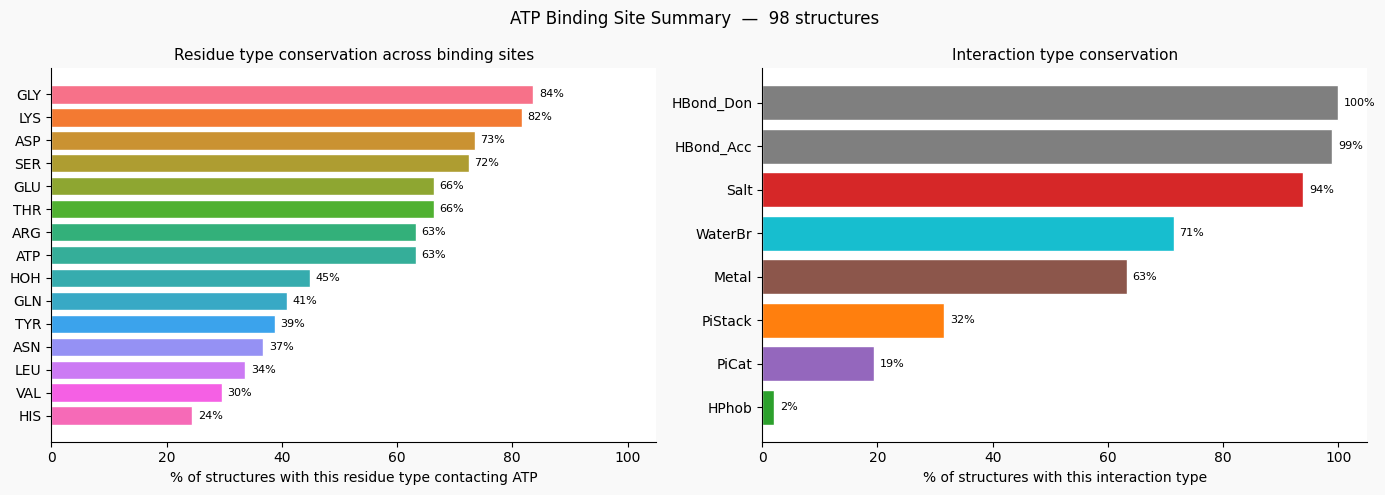

Saved interaction_summary.png


In [11]:
n_structs = df_all['pdb_id'].nunique()

# Conservation: % of structures with at least one contact of this residue type
res_conservation = (
    df_all.drop_duplicates(['pdb_id', 'res_type'])
          .groupby('res_type')['pdb_id']
          .count()
          .sort_values(ascending=False)
          / n_structs * 100
).head(15)

itype_conservation = (
    df_all.drop_duplicates(['pdb_id', 'itype'])
          .groupby('itype')['pdb_id']
          .count()
          .sort_values(ascending=False)
          / n_structs * 100
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#f9f9f9')

# Residue conservation
palette = sns.color_palette('husl', len(res_conservation))
axes[0].barh(res_conservation.index, res_conservation.values,
             color=palette, edgecolor='white')
axes[0].set_xlabel('% of structures with this residue type contacting ATP')
axes[0].set_title('Residue type conservation across binding sites', fontsize=11)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 105)
for v, label in zip(res_conservation.values, res_conservation.index):
    axes[0].text(v + 1, label, f'{v:.0f}%', va='center', fontsize=8)
for spine in ['top', 'right']:
    axes[0].spines[spine].set_visible(False)

# Interaction type conservation
icolors = [ITYPE_COLOR.get(i, '#7f7f7f') for i in itype_conservation.index]
axes[1].barh(itype_conservation.index, itype_conservation.values,
             color=icolors, edgecolor='white')
axes[1].set_xlabel('% of structures with this interaction type')
axes[1].set_title('Interaction type conservation', fontsize=11)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 105)
for v, label in zip(itype_conservation.values, itype_conservation.index):
    axes[1].text(v + 1, label, f'{v:.0f}%', va='center', fontsize=8)
for spine in ['top', 'right']:
    axes[1].spines[spine].set_visible(False)

plt.suptitle(f'ATP Binding Site Summary  \u2014  {n_structs} structures', fontsize=12)
plt.tight_layout()
fig.savefig(Path(PLOT_DIR) / 'interaction_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved interaction_summary.png')

---
## Step 9 — Design insights for complementary binding proteins

The table and plot below summarise which ATP faces are **over-engaged** by the
native protein and which are **most exposed** — the exposed faces are the
prime targets for a designed complementary binder.

**Conceptual design rules:**
1. **γ-phosphate reader** — The most nucleotide-specific handle. Design a Lys/Arg
   loop that coordinates the γ-phosphate; the complex only forms when ATP (not ADP)
   is present.
2. **Adenine face stacking** — Aromatic (Phe, Tyr, Trp) residues stacking on the
   adenine ring are highly conserved but often engage only one face. A complementary
   binder can cap the other face.
3. **Ribose hydroxyl H-bonds** — Ser/Thr H-bonds to the 2'- and 3'-OH groups add
   ATP vs. GTP selectivity.
4. **Neoepitope strategy** — Look for clusters where ATP binding exposes a flat
   surface on the protein (β-strand, helix face). That surface is the induced
   assembly site for a second protein.

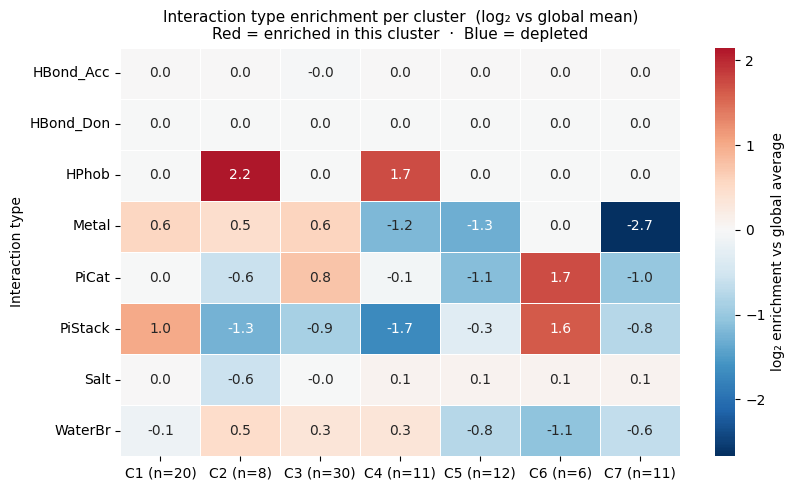

Saved cluster_enrichment.png


In [12]:
# Per-cluster: which interaction types are enriched vs the global average?
global_freq = itype_conservation / 100  # as fraction

enrichment = {}
for cid in range(1, N_CLUSTERS + 1):
    members = fp[fp['cluster'] == cid].index.tolist()
    cl_df   = df_all[df_all['pdb_id'].isin(members)]
    n_cl    = len(members)
    cl_freq = (
        cl_df.drop_duplicates(['pdb_id', 'itype'])
             .groupby('itype')['pdb_id']
             .count() / n_cl
    )
    # log2 enrichment vs global
    enrich = np.log2((cl_freq + 0.01) / (global_freq + 0.01))
    enrichment[f'C{cid} (n={n_cl})'] = enrich

enrich_df = pd.DataFrame(enrichment).fillna(0)

fig, ax = plt.subplots(figsize=(max(8, N_CLUSTERS * 1.2), 5))
sns.heatmap(
    enrich_df,
    ax=ax,
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    linecolor='white',
    annot=True,
    fmt='.1f',
    cbar_kws={'label': 'log\u2082 enrichment vs global average'},
)
ax.set_title(
    'Interaction type enrichment per cluster  (log\u2082 vs global mean)\n'
    'Red = enriched in this cluster  ·  Blue = depleted',
    fontsize=11
)
ax.set_ylabel('Interaction type')
plt.tight_layout()
fig.savefig(Path(PLOT_DIR) / 'cluster_enrichment.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved cluster_enrichment.png')

---
## Step 10 — Export cluster summaries
Saves a JSON summary of each cluster (member PDB IDs and top signature features)
for downstream use.

In [13]:
summary = []
for cid in range(1, N_CLUSTERS + 1):
    members = fp[fp['cluster'] == cid].index.tolist()
    cl_df   = df_all[df_all['pdb_id'].isin(members)]

    top = (
        cl_df.drop_duplicates(['pdb_id', 'res_type', 'itype'])
             .groupby(['res_type', 'itype'])
             .size()
             .reset_index(name='n')
             .sort_values('n', ascending=False)
             .head(8)
    )
    summary.append({
        'cluster': cid,
        'n_structures': len(members),
        'pdb_ids': members,
        'signature_features': [
            {'res_type': r, 'itype': i, 'n_structs': int(n)}
            for r, i, n in zip(top['res_type'], top['itype'], top['n'])
        ],
    })

out_path = Path(OUTPUT_DIR) / 'cluster_summary.json'
with open(out_path, 'w') as f:
    json.dump(summary, f, indent=2)

print(f'Saved {out_path}')
print(f'\nOutput files in {OUTPUT_DIR}/')
for p in sorted(Path(OUTPUT_DIR).iterdir()):
    if p.is_file():
        print(f'  {p.name:40s}  {p.stat().st_size // 1024:6d} KB')

Saved output/binding/cluster_summary.json

Output files in output/binding/
  atp_interactions.csv                         162 KB
  cluster_assignments.csv                        0 KB
  cluster_summary.json                           7 KB
